# Shallow Neural Networks
### From one neuron to a hidden layer, built from scratch in NumPy

**What we already know:** a single neuron (the perceptron / logistic unit), activation functions, and how SGD updates weights.

**What's new in this chapter:**

| # | Section | The one idea to take away |
|---|---------|---------------------------|
| 1 | The economics problem | Some economic decisions have *curved* boundaries |
| 2 | One neuron fails | A single neuron can only draw a straight line |
| 3 | The forward pass | A hidden layer is just "many neurons side by side, then one more neuron" |
| 4 | Hidden units are bent lines | Adding ReLUs builds any shape, shown on **real wage data** |
| 5 | Backpropagation | Blame flows backwards with the chain rule, the same SGD update as before |
| 6 | Training & looking inside | Watching the network learn the profit region |
| 7 | Practical issues | Initialization, choice of activation, number of hidden units |
| 8 | Bridge to PyTorch | `loss.backward()` computes *exactly* what we derived by hand |
| 9 | Reality check | A neural network only helps when there is non-linearity to find |

> Everything up to Section 8 uses only NumPy. That's deliberate: the point is to *see* every number move.

The ideas behind this notebook are from Simon Prince's "Understanding Deep Learning Book", especially overlying the Hidden Units, as well as Mike Cohen's "Deep Understanding of Deep Learning (DUDL)" course in Udemy which for me was the first course to go so deep into PyTorch and Deep Learning theory and practice.

In [1]:
# Upload the packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch
# real econometrics datasets (Wooldridge's textbook), bundled offline
import wooldridge

In [2]:
# Parameters for visualization
BLUE, ORANGE, AQUA, VIOLET, GRAY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6", "#9a9890", "#2b2b2b"
PROB_CMAP = LinearSegmentedColormap.from_list("prob", [ORANGE, "#f4f3ef", BLUE])  # orange = loss, blue = profit
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 11, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#8a8984",
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False, "lines.linewidth": 2,
})

np.set_printoptions(precision=3, suppress=True)

---
## 1. The economics problem: *will this coffee shop make a profit?*

The **NociCaff** Coffee shop in Astiri chooses a **price** $p$ (€ per cup) and has a **unit cost** $c$ (€ per cup: beans, milk, wages).
Demand is downward sloping, and there is a **fixed cost** $F$ (rent) to pay every day (Basic Economic Theory: $Q = a - bp$):

$$\text{Demand: } Q = 10 - p \qquad\qquad \text{Profit: } \pi = (p - c)\cdot Q - F$$

The shop is profitable if $\pi > 0$. The rent varies a bit from shop to shop, so the data is noisy.

**Why is this interesting?** Look at the profit curves on the left below:
- price **too low** → each cup loses money (or earns too little to pay the rent)
- price **too high** → nobody buys
- profit is only possible in a **band** of prices in the middle, and that band **shrinks as costs rise** until it disappears.

So in the (cost, price) plane the profitable shops form a curved, tongue-shaped region, which *No straight line can separate*

**Me at it again, doing what I love best: building simulations. Check out my latest artificial dataset!**

In [3]:
# Simulate 600 coffee shops
rng = np.random.default_rng(0)
n = 600
# unit cost, € per cup
cost  = rng.uniform(0, 8, n)
# price charged, € per cup
price = rng.uniform(0, 13, n)
# fixed cost, varies by shop
rent  = 5 + rng.normal(0, 1.0, n)

# nobody buys above €10
demand = np.maximum(10 - price, 0)
profit = (price - cost) * demand - rent
# 1 = profitable, 0 = loss
y = (profit > 0).astype(float)

shops = pd.DataFrame({"cost": cost, "price": price, "profit": profit.round(2), "profitable": y.astype(int)})
print(f"{n} shops, {y.mean():.0%} of them are profitable")
shops.head()

600 shops, 26% of them are profitable


,cost,price,profit,profitable
0,5.095693,0.080299,-55.83,0
1,2.158294,9.375155,-1.79,0
2,0.327788,8.795858,4.73,1
3,0.132221,8.539719,7.89,1
4,6.506162,8.936395,-1.86,0


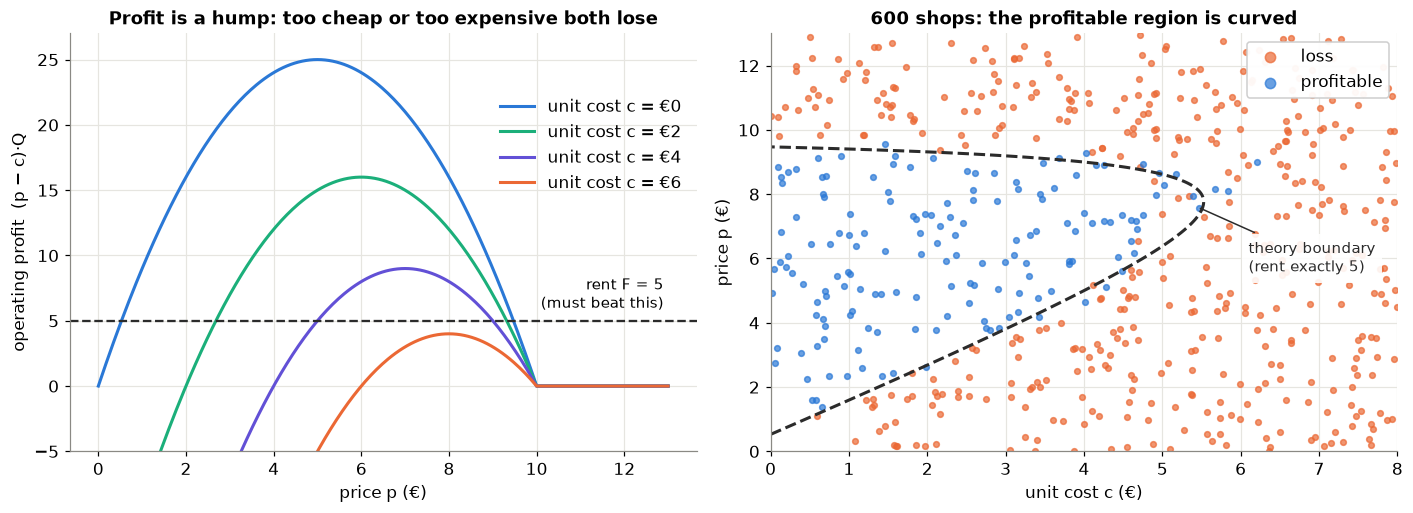

In [4]:
# Remember the Profit Curve from "AI in BUsiness" Course
fig, (axL, axR) = plt.subplots(1, 2, figsize=(13, 4.8))

# Left: the economics, profit as a function of price for a few cost levels
pp = np.linspace(0, 13, 300)
for c_, col in zip([0, 2, 4, 6], [BLUE, AQUA, VIOLET, ORANGE]):
    axL.plot(pp, (pp - c_) * np.maximum(10 - pp, 0), color=col, label=f"unit cost c = €{c_}")
axL.axhline(5, color=INK, ls="--", lw=1.5)
axL.text(12.9, 5.6, "rent F = 5\n(must beat this)", ha="right", va="bottom", fontsize=10)
axL.set(xlabel="price p (€)", ylabel="operating profit  (p − c)·Q", ylim=(-5, 27),
        title="Profit is a hump: too cheap or too expensive both lose")
axL.legend(loc="upper right", bbox_to_anchor=(1, 0.88))

# Right: the data, with the theoretical boundary (rent = 5 exactly)
C, P = np.meshgrid(np.linspace(0, 8, 300), np.linspace(0, 13, 300))
axR.scatter(cost[y == 0], price[y == 0], s=14, color=ORANGE, alpha=.7, label="loss")
axR.scatter(cost[y == 1], price[y == 1], s=14, color=BLUE, alpha=.7, label="profitable")
axR.contour(C, P, (P - C) * np.maximum(10 - P, 0) - 5, levels=[0], colors=INK, linewidths=2, linestyles="--")
axR.set(xlabel="unit cost c (€)", ylabel="price p (€)", title="600 shops: the profitable region is curved")
axR.legend(loc="upper right", frameon=True, facecolor="white", framealpha=.95, markerscale=1.8)
axR.annotate("theory boundary\n(rent exactly 5)", xy=(5.45, 7.6), xytext=(6.1, 5.6), fontsize=10, color=INK,
             bbox=dict(fc="white", ec="none", alpha=.9), arrowprops=dict(arrowstyle="-", color=INK))
plt.tight_layout(); plt.show()

Before training anything we **standardize** the two inputs (mean 0, std 1). The network then sees numbers of similar size, which keeps gradient descent stable. We already did this in the SGD chapter.

In [5]:
# shape (600, 2)
X_raw = np.c_[cost, price]
X_mean, X_std = X_raw.mean(0), X_raw.std(0)
X = (X_raw - X_mean) / X_std
# shape (600, 1): a column vector
Y = y[:, None]
print("X:", X.shape, "  Y:", Y.shape)

X: (600, 2)   Y: (600, 1)


In [6]:
# helper used for every decision-boundary picture in this chapter
GRID_C, GRID_P = np.meshgrid(np.linspace(0, 8, 200), np.linspace(0, 13, 200))
GRID = (np.c_[GRID_C.ravel(), GRID_P.ravel()] - X_mean) / X_std

def plot_boundary(ax, predict_proba, title="", points=True):
    # Shade P(profitable) over the (cost, price) plane; draw the 50% line.
    prob = predict_proba(GRID).reshape(GRID_C.shape)
    ax.contourf(GRID_C, GRID_P, prob, levels=np.linspace(0, 1, 21), cmap=PROB_CMAP, alpha=.85)
    ax.contour(GRID_C, GRID_P, prob, levels=[.5], colors=INK, linewidths=2)
    if points:
        ax.scatter(cost, price, c=np.where(y == 1, BLUE, ORANGE), s=7, alpha=.55, edgecolors="none")
    ax.set(xlabel="unit cost c (€)", ylabel="price p (€)", title=title)
    ax.grid(False)

## 2. One neuron is not enough

Recap from the last chapter: a single neuron computes $\hat p = \sigma(w_1 x_1 + w_2 x_2 + b)$.

The boundary $\hat p = 0.5$ is where $w_1 x_1 + w_2 x_2 + b = 0$, and that is **always a straight line**.

Let's train one with SGD and see what it does.

single neuron accuracy: 75.8% (predicting 'always loss' would give 73.7%)


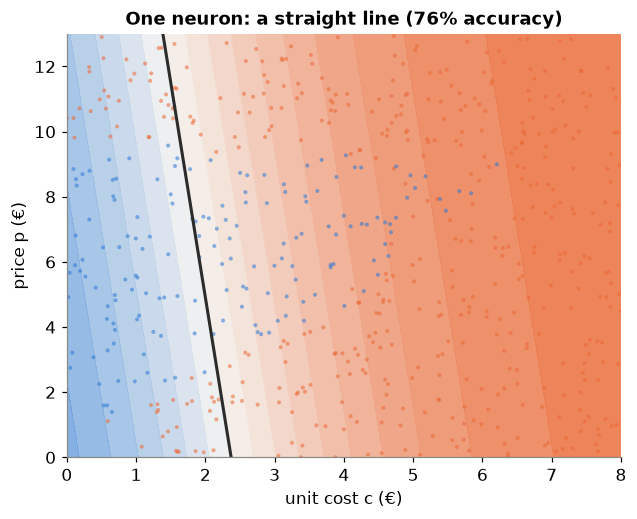

In [7]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# binary cross-entropy (log loss)
def bce(p, y):
    p = np.clip(p, 1e-9, 1 - 1e-9)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

w, b = np.zeros((2, 1)), 0.0
for epoch in range(2000):
    p_hat = sigmoid(X @ w + b)
    grad_z = (p_hat - Y) / n
    w -= 1.0 * X.T @ grad_z
    b -= 1.0 * grad_z.sum()

acc_single = ((p_hat > .5) == Y).mean()
print(f"single neuron accuracy: {acc_single:.1%} (predicting 'always loss' would give {1 - y.mean():.1%})")

fig, ax = plt.subplots(figsize=(6.5, 5))
plot_boundary(ax, lambda G: sigmoid(G @ w + b), f"One neuron: a straight line ({acc_single:.0%} accuracy)")
plt.show()

The single neuron is barely better than saying **"no shop is ever profitable"**. It can tilt and shift its line, but it can't bend it.

**Idea:** what if we had *several* neurons, each drawing its own line, and then a final neuron that **combines** their opinions? That is a shallow neural network.

## 3. The forward pass: inputs → hidden layer → output

A network with **one hidden layer** of $H$ units:

| Step | Formula | Shape (for $n$ shops, $H$ hidden units) | In words |
|---|---|---|---|
| input | $X$ | $(n, 2)$ | cost and price of each shop |
| hidden pre-activation | $Z_1 = X W_1 + b_1$ | $(n, 2)\cdot(2, H) \to (n, H)$ | $H$ neurons, each a weighted sum of the inputs |
| hidden activation | $A_1 = \text{ReLU}(Z_1)$ | $(n, H)$ | each neuron "switches on" only on one side of its line |
| output pre-activation | $z_2 = A_1 W_2 + b_2$ | $(n, H)\cdot(H, 1) \to (n, 1)$ | one final neuron weighing the hidden opinions |
| output | $\hat p = \sigma(z_2)$ | $(n, 1)$ | probability the shop is profitable |

**Rule of thumb for shapes:** a weight matrix is `(inputs coming in, neurons in this layer)`.

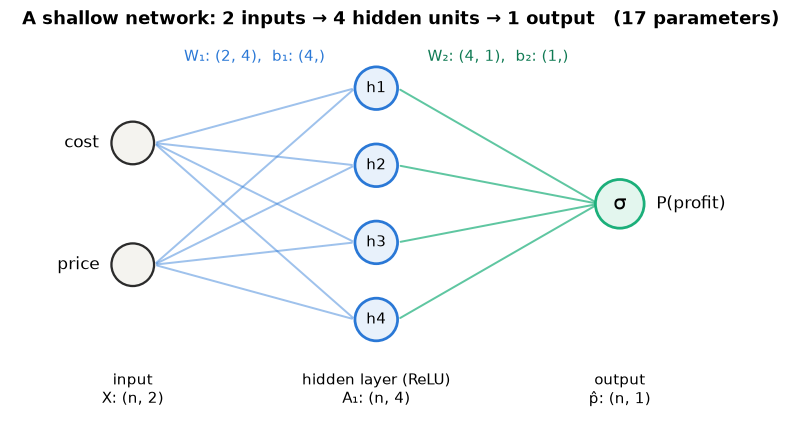

In [8]:
def draw_network(n_in=2, n_hidden=4, in_labels=("cost", "price"), out_label="P(profit)"):
    fig, ax = plt.subplots(figsize=(10, 4.6)); ax.axis("off"); ax.set_aspect("equal")
    xs = [0, 4, 8]
    ys_in  = np.linspace(1, -1, n_in) * 1.0
    ys_hid = np.linspace(1, -1, n_hidden) * 1.9
    for yi in ys_in:
        for yh in ys_hid:
            ax.add_patch(FancyArrowPatch((xs[0] + .35, yi), (xs[1] - .35, yh), arrowstyle="-", color=BLUE, alpha=.45, lw=1.3))
    for yh in ys_hid:
        ax.add_patch(FancyArrowPatch((xs[1] + .35, yh), (xs[2] - .35, 0), arrowstyle="-", color=AQUA, alpha=.7, lw=1.3))
    for yi, lab in zip(ys_in, in_labels):
        ax.add_patch(Circle((xs[0], yi), .35, color="#f4f3ef", ec=INK, lw=1.5)); ax.text(xs[0] - .55, yi, lab, ha="right", va="center")
    for k, yh in enumerate(ys_hid):
        ax.add_patch(Circle((xs[1], yh), .35, color="#e8f1fb", ec=BLUE, lw=1.8)); ax.text(xs[1], yh, f"h{k+1}", ha="center", va="center", fontsize=10)
    ax.add_patch(Circle((xs[2], 0), .4, color="#e3f6ee", ec=AQUA, lw=1.8)); ax.text(xs[2], 0, "σ", ha="center", va="center", fontsize=14)
    ax.text(xs[2] + .6, 0, out_label, va="center")
    ax.text(xs[0], -2.75, "input\nX: (n, 2)", ha="center", va="top", fontsize=10)
    ax.text(xs[1], -2.75, f"hidden layer (ReLU)\nA₁: (n, {n_hidden})", ha="center", va="top", fontsize=10)
    ax.text(xs[2], -2.75, "output\np̂: (n, 1)", ha="center", va="top", fontsize=10)
    ax.text(2, 2.35, f"W₁: (2, {n_hidden}),  b₁: ({n_hidden},)", ha="center", color=BLUE, fontsize=10)
    ax.text(6, 2.35, f"W₂: ({n_hidden}, 1),  b₂: (1,)", ha="center", color="#0f7a53", fontsize=10)
    ax.set_xlim(-2, 10.8); ax.set_ylim(-3.6, 2.8)
    ax.set_title(f"A shallow network: {n_in} inputs → {n_hidden} hidden units → 1 output   "
                 f"({n_in*n_hidden + n_hidden + n_hidden + 1} parameters)")
    plt.show()

draw_network()

Let's push **three shops** through a small network with random weights and print every intermediate step. Nothing is trained yet. The point is only to see the shapes and the numbers flow through.

I would suggest you take a piece of paper and do these matrix multiplications by hand to understand them if your Linear Algebra is rusty

In [9]:
def relu(z):
    return np.maximum(0, z)

rng_demo = np.random.default_rng(42)
H = 4
W1 = rng_demo.normal(0, 1, (2, H)); b1 = np.zeros(H)
W2 = rng_demo.normal(0, 1, (H, 1)); b2 = np.zeros(1)

X3 = X[:3]
print("raw inputs (cost €, price €):\n", X_raw[:3].round(2))
print("\nstandardized X        shape", X3.shape, "\n", X3)
print("\nW1 Weight Matrix,    shape", W1.shape, "\n", W1)
print("\nW2 Weight Matrix,    shape", W2.shape, "\n", W2)
print("\nb1 Weight Matrix,    shape", b1.shape, "\n", b1)
print("\nb2 Weight Matrix,    shape", b2.shape, "\n", b2)
Z1 = X3 @ W1 + b1;  print("\nZ1 = X W1 + b1        shape", Z1.shape, "\n", Z1)
A1 = relu(Z1);      print("\nA1 = ReLU(Z1)         shape", A1.shape, " <- negatives become 0: those units are 'off'\n", A1)
z2 = A1 @ W2 + b2;  print("\nz2 = A1 W2 + b2       shape", z2.shape, "\n", z2)
p_hat3 = sigmoid(z2); print("\np̂ = σ(z2)             shape", p_hat3.shape, "\n", p_hat3)
print("\ntrue labels:", y[:3])

raw inputs (cost €, price €):
 [[5.1  0.08]
 [2.16 9.38]
 [0.33 8.8 ]]

standardized X        shape (3, 2) 
 [[ 0.39  -1.719]
 [-0.892  0.779]
 [-1.691  0.623]]

W1 Weight Matrix,    shape (2, 4) 
 [[ 0.305 -1.04   0.75   0.941]
 [-1.951 -1.302  0.128 -0.316]]

W2 Weight Matrix,    shape (4, 1) 
 [[-0.017]
 [-0.853]
 [ 0.879]
 [ 0.778]]

b1 Weight Matrix,    shape (4,) 
 [0. 0. 0. 0.]

b2 Weight Matrix,    shape (1,) 
 [0.]

Z1 = X W1 + b1        shape (3, 4) 
 [[ 3.472  1.833  0.073  0.91 ]
 [-1.792 -0.086 -0.57  -1.086]
 [-1.731  0.947 -1.19  -1.788]]

A1 = ReLU(Z1)         shape (3, 4)  <- negatives become 0: those units are 'off'
 [[3.472 1.833 0.073 0.91 ]
 [0.    0.    0.    0.   ]
 [0.    0.947 0.    0.   ]]

z2 = A1 W2 + b2       shape (3, 1) 
 [[-0.85 ]
 [ 0.   ]
 [-0.808]]

p̂ = σ(z2)             shape (3, 1) 
 [[0.299]
 [0.5  ]
 [0.308]]

true labels: [0. 0. 1.]


## 4. Why a hidden layer helps: **hidden units are bent lines**

In order to understand the intuition of this chapter, so we'll do it in **1D** where everything can be drawn. Then you can scale it up for higher dimensions

One ReLU hidden unit computes $w_2\cdot\text{ReLU}(w_1 x + b_1)$. That's a line that is **flat, then bends** at the point $x = -b_1/w_1$:
- $b_1$ moves the **kink** left or right
- $w_1$ (together with $w_2$) sets the **slope** after the kink
- the sign of $w_2$ decides whether it bends **up or down**

Add several of these together and you can build *any* curve out of straight pieces.

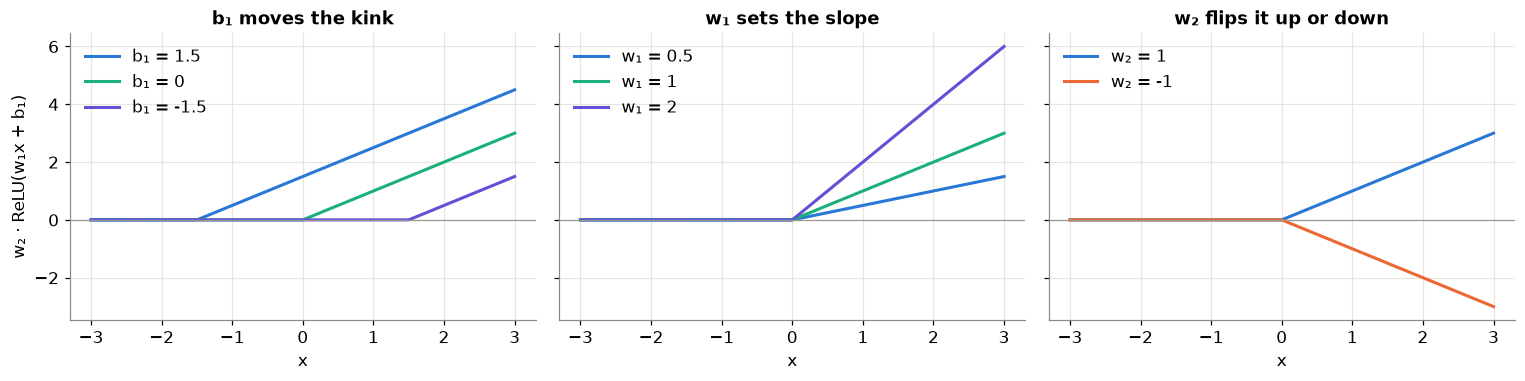

In [10]:
xx = np.linspace(-3, 3, 400)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
for b_, col in zip([1.5, 0, -1.5], [BLUE, AQUA, VIOLET]):
    axes[0].plot(xx, relu(xx + b_), color=col, label=f"b₁ = {b_}")
axes[0].set_title("b₁ moves the kink")
for w_, col in zip([0.5, 1, 2], [BLUE, AQUA, VIOLET]):
    axes[1].plot(xx, relu(w_ * xx), color=col, label=f"w₁ = {w_}")
axes[1].set_title("w₁ sets the slope")
for w2_, col in zip([1, -1], [BLUE, ORANGE]):
    axes[2].plot(xx, w2_ * relu(xx), color=col, label=f"w₂ = {w2_}")
axes[2].set_title("w₂ flips it up or down")
for a in axes: a.legend(loc="upper left"); a.set_xlabel("x"); a.axhline(0, color=GRAY, lw=.8)
axes[0].set_ylabel("w₂ · ReLU(w₁x + b₁)")
plt.tight_layout(); plt.show()

### Real data: the age-earnings profile

Labour economists know that wages rise quickly early in a career, flatten out, and eventually fall: the **concave experience–earnings profile** (Mincer). The usual econometric fix is to add $\text{exper}^2$ to a regression.

Here we use the real `wage1` dataset (526 US workers, 1976 Current Population Survey) and ask: *can a network discover the curve on its own, out of bent lines?* You can read more on the dataset from the documentation: J.M. Wooldridge (2019) Introductory Econometrics: A Modern Approach, Cengage Learning, 7th edition.

First, **by hand**: three ReLU units with weights we choose ourselves.

In [11]:
# Get the real data from woolridge package installed above
wage1 = wooldridge.data("wage1")
print(type(wage1))
wage1.head()

<class 'pandas.DataFrame'>


,wage,educ,exper,tenure,nonwhite,female,married,numdep,smsa,northcen,...,trcommpu,trade,services,profserv,profocc,clerocc,servocc,lwage,expersq,tenursq
0,3.10,11,2,0,0,1,0,2,1,0,...,0,0,0,0,0,0,0,1.131402,4,0
1,3.24,12,22,2,0,1,1,3,1,0,...,0,0,1,0,0,0,1,1.175573,484,4
2,3.00,11,2,0,0,0,0,2,0,0,...,0,1,0,0,0,0,0,1.098612,4,0
3,6.00,8,44,28,0,0,1,0,1,0,...,0,0,0,0,0,1,0,1.791759,1936,784
4,5.30,12,7,2,0,0,1,1,0,0,...,0,0,0,0,0,0,0,1.667707,49,4


In [12]:
wage1.info()

<class 'pandas.DataFrame'>
RangeIndex: 526 entries, 0 to 525
Data columns (total 24 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   wage      526 non-null    float64
 1   educ      526 non-null    int64  
 2   exper     526 non-null    int64  
 3   tenure    526 non-null    int64  
 4   nonwhite  526 non-null    int64  
 5   female    526 non-null    int64  
 6   married   526 non-null    int64  
 7   numdep    526 non-null    int64  
 8   smsa      526 non-null    int64  
 9   northcen  526 non-null    int64  
 10  south     526 non-null    int64  
 11  west      526 non-null    int64  
 12  construc  526 non-null    int64  
 13  ndurman   526 non-null    int64  
 14  trcommpu  526 non-null    int64  
 15  trade     526 non-null    int64  
 16  services  526 non-null    int64  
 17  profserv  526 non-null    int64  
 18  profocc   526 non-null    int64  
 19  clerocc   526 non-null    int64  
 20  servocc   526 non-null    int64  
 21  lwag

In [13]:
# years of experience
exper = wage1["exper"].values.astype(float)
# log hourly wage
logw  = np.log(wage1["wage"].values)
print(f"{len(exper)} workers, experience from {exper.min():.0f} to {exper.max():.0f} years")

526 workers, experience from 1 to 51 years


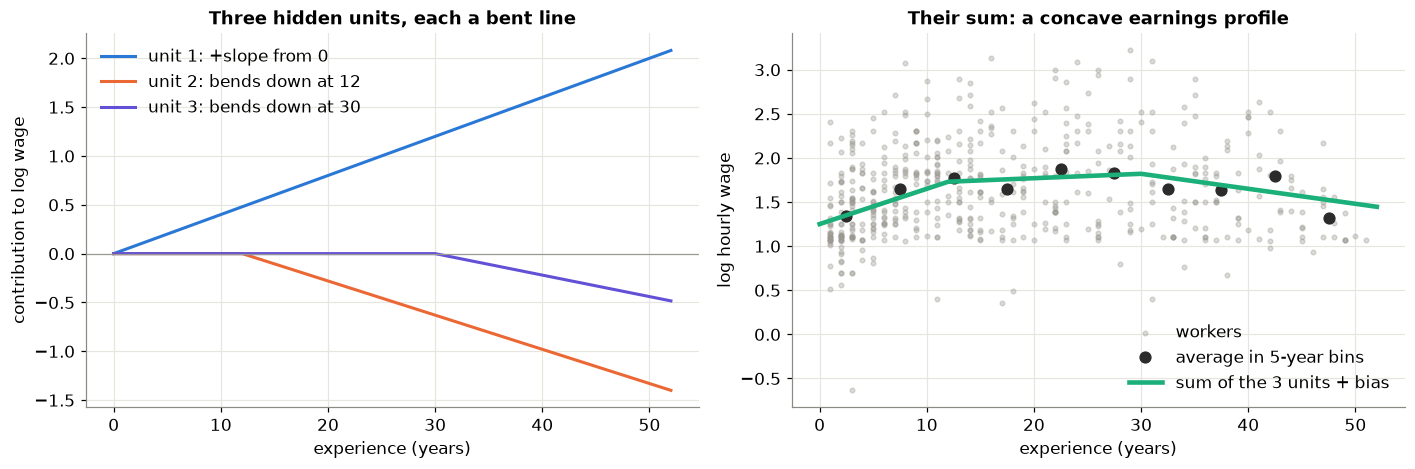

In [14]:
# binned averages: what the "true" profile looks like
bins = np.arange(0, 55, 5)
mid = (bins[:-1] + bins[1:]) / 2
bin_mean = [logw[(exper >= lo) & (exper < hi)].mean() for lo, hi in zip(bins[:-1], bins[1:])]

# three hand-crafted bent lines (in years of experience directly)
ex = np.linspace(0, 52, 400)
base = 1.25

# rises from the start...
u1 =  0.040 * relu(ex - 0)
# ...flattens after ~12 years...
u2 = -0.035 * relu(ex - 12)
# ...and declines after ~30 years
u3 = -0.022 * relu(ex - 30)
total = base + u1 + u2 + u3

fig, (axA, axB) = plt.subplots(1, 2, figsize=(13, 4.4))
for u, lab, col in [(u1, "unit 1: +slope from 0", BLUE), (u2, "unit 2: bends down at 12", ORANGE), (u3, "unit 3: bends down at 30", VIOLET)]:
    axA.plot(ex, u, color=col, label=lab)
axA.axhline(0, color=GRAY, lw=.8)
axA.set(title="Three hidden units, each a bent line", xlabel="experience (years)", ylabel="contribution to log wage")
axA.legend()

axB.scatter(exper, logw, s=9, color=GRAY, alpha=.35, label="workers")
axB.plot(mid, bin_mean, "o", color=INK, ms=7, label="average in 5-year bins")
axB.plot(ex, total, color=AQUA, lw=3, label="sum of the 3 units + bias")
axB.set(title="Their sum: a concave earnings profile", xlabel="experience (years)", ylabel="log hourly wage")
axB.legend(loc="lower right")
plt.tight_layout(); plt.show()

We built a realistic wage profile from three "kinks", with no $\text{exper}^2$ needed.

In practice we don't want to place the kinks by hand: the network should **find** them itself, by gradient descent. For that we need the gradient of the loss with respect to *every* weight, including the hidden ones. That is backpropagation, the next section. We'll come back to this wage data as soon as we can train.

## 5. Backpropagation: who is to blame for the error?

Training means: **change each weight a little in the direction that reduces the loss.** That's SGD, exactly as before:

$$W \leftarrow W - \eta \,\frac{\partial L}{\partial W}$$

The only new problem: $W_1$ doesn't touch the loss directly. It affects $Z_1$, which affects $A_1$, which affects $z_2$, which affects $\hat p$, which affects $L$. The **chain rule** says: multiply the sensitivities along the path.

**Picture it as a chain of people passing a message.** The forward pass passes *predictions* to the right. The backward pass passes *blame* to the left: each step asks "how much did *my* output contribute to the error?" and hands that blame to whoever fed it.

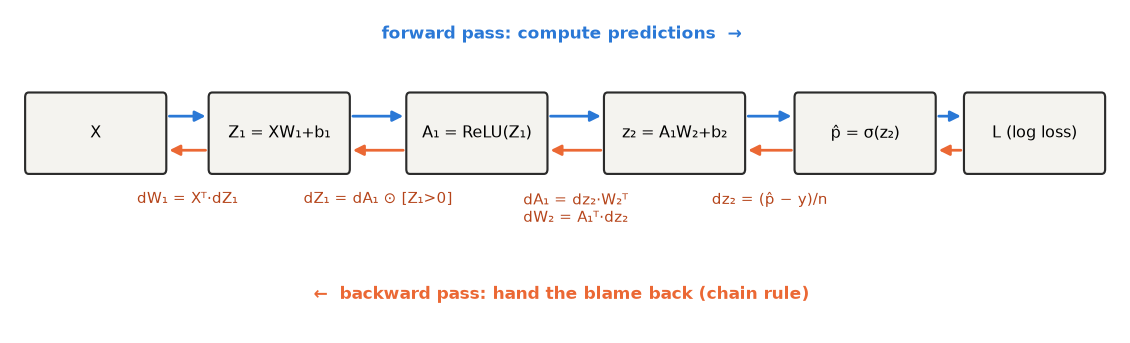

In [15]:
fig, ax = plt.subplots(figsize=(13, 3.8)); ax.axis("off")
nodes = [("X", 0), ("Z₁ = XW₁+b₁", 2.6), ("A₁ = ReLU(Z₁)", 5.4), ("z₂ = A₁W₂+b₂", 8.2), ("p̂ = σ(z₂)", 10.9), ("L (log loss)", 13.3)]
for lab, x0 in nodes:
    ax.add_patch(FancyBboxPatch((x0 - .95, -.38), 1.9, .76, boxstyle="round,pad=0.05", fc="#f4f3ef", ec=INK, lw=1.4))
    ax.text(x0, 0, lab, ha="center", va="center", fontsize=10.5)
back = ["dW₁ = Xᵀ·dZ₁", "dZ₁ = dA₁ ⊙ [Z₁>0]", "dA₁ = dz₂·W₂ᵀ\ndW₂ = A₁ᵀ·dz₂", "dz₂ = (p̂ − y)/n", ""]
for i in range(len(nodes) - 1):
    x_a, x_b = nodes[i][1], nodes[i + 1][1]
    ax.add_patch(FancyArrowPatch((x_a + 1.0, .18), (x_b - 1.0, .18), arrowstyle="-|>", mutation_scale=14, color=BLUE, lw=1.8))
    ax.add_patch(FancyArrowPatch((x_b - 1.0, -.18), (x_a + 1.0, -.18), arrowstyle="-|>", mutation_scale=14, color=ORANGE, lw=1.8))
    if back[i]:
        ax.text((x_a + x_b) / 2, -.62, back[i], ha="center", va="top", fontsize=9.5, color="#b5441a")
ax.text(6.6, 1.0, "forward pass: compute predictions  →", color=BLUE, ha="center", fontsize=11, weight="bold")
ax.text(6.6, -1.75, "←  backward pass: hand the blame back (chain rule)", color=ORANGE, ha="center", fontsize=11, weight="bold")
ax.set_xlim(-1.2, 14.5); ax.set_ylim(-2.1, 1.3); plt.show()

### The four gradient rules, step by step

We go **right to left**. The notation $dA$ means "$\partial L / \partial A$, the blame arriving at $A$". Every $dA$ has **the same shape as $A$** (a useful sanity check).

**① Output.** For sigmoid + log loss the derivative simplifies beautifully (we saw this for the single neuron):
$$dz_2 = \frac{1}{n}(\hat p - y) \qquad (n,1)$$
*Intuition:* the blame is just "prediction minus truth".

**② Output layer weights.** $z_2 = A_1 W_2 + b_2$, so the blame on $W_2$ is "how active was each hidden unit" × "how wrong was the output":
$$dW_2 = A_1^\top dz_2 \;\;(H,1) \qquad db_2 = \textstyle\sum_i dz_2 \;\;(1,)$$

**③ Back into the hidden layer.** Each hidden unit gets blame in proportion to the weight connecting it to the output:
$$dA_1 = dz_2\, W_2^\top \qquad (n,H)$$

**④ Through the ReLU.** ReLU passes blame through where it was "on" and blocks it where it was "off" (slope 1 or 0):
$$dZ_1 = dA_1 \odot \mathbb 1[Z_1 > 0] \qquad (n,H)$$
then, exactly like step ②:
$$dW_1 = X^\top dZ_1 \;\;(2,H) \qquad db_1 = \textstyle\sum_i dZ_1 \;\;(H,)$$

Notice the pattern: **every layer does the same two things.** It computes its weight gradient as (input)ᵀ × (blame), and it passes the blame back through its weights and its activation. Deeper networks just repeat this.

In [16]:
# activation functions and their derivatives: We saw them the previous week without going into details
# Here, if you understand OOP, this code is a piece of cake, otherwise you can ask AI what it does
ACTIVATIONS = {
    "relu":    (lambda z: np.maximum(0, z),        lambda z, a: (z > 0).astype(float)),
    "sigmoid": (lambda z: 1 / (1 + np.exp(-z)),    lambda z, a: a * (1 - a)),
    "tanh":    (np.tanh,                           lambda z, a: 1 - a ** 2),
}

class ShallowNet:
    # One hidden layer. output='sigmoid' -> log loss (classification); output='linear' -> MSE (regression).
    def __init__(self, n_in, n_hidden, activation="relu", output="sigmoid", init="random", seed=0):
        rng = np.random.default_rng(seed)
        if init == "same":     # every hidden unit starts with identical weights (zero is the extreme case)
            self.W1 = np.full((n_in, n_hidden), 0.5); self.W2 = np.full((n_hidden, 1), 0.1)
        else:   # scaled random init (He-style): keeps the signal size roughly constant layer to layer
            self.W1 = rng.normal(0, np.sqrt(2 / n_in), (n_in, n_hidden))
            self.W2 = rng.normal(0, np.sqrt(1 / n_hidden), (n_hidden, 1))
        self.b1 = np.full(n_hidden, 0.1) if init == "same" else rng.normal(0, 0.5, n_hidden)
        self.b2 = np.zeros(1)
        self.act, self.act_grad = ACTIVATIONS[activation]
        self.output = output

    def params(self):
        return {"W1": self.W1, "b1": self.b1, "W2": self.W2, "b2": self.b2}

    # forward
    def forward(self, X):
        self.X  = X
        self.Z1 = X @ self.W1 + self.b1
        self.A1 = self.act(self.Z1)
        self.z2 = self.A1 @ self.W2 + self.b2
        self.out = sigmoid(self.z2) if self.output == "sigmoid" else self.z2
        return self.out

    def loss(self, Y):
        if self.output == "sigmoid":
            return bce(self.out, Y)
        return np.mean((self.out - Y) ** 2)

    # backward: the four rules explained above put into code
    def backward(self, Y):
        n = len(Y)
        # rule 1
        dz2 = (self.out - Y) / n if self.output == "sigmoid" else 2 * (self.out - Y) / n 
        # rule 2
        dW2 = self.A1.T @ dz2;  db2 = dz2.sum(0)
        # rule 3
        dA1 = dz2 @ self.W2.T
        # rule 4
        dZ1 = dA1 * self.act_grad(self.Z1, self.A1)
        dW1 = self.X.T @ dZ1;   db1 = dZ1.sum(0)
        return {"W1": dW1, "b1": db1, "W2": dW2, "b2": db2}

    def step(self, grads, lr):
        # plain SGD
        for name, p in self.params().items():
            p -= lr * grads[name]

    def predict(self, X):
        return self.forward(X)[:, 0]

### Did we get the calculus right? A gradient check

Hand-derived gradients are easy to get wrong. The classic test: nudge one weight by a tiny $\varepsilon$ and see how much the loss changes:

$$\frac{\partial L}{\partial w} \approx \frac{L(w+\varepsilon) - L(w-\varepsilon)}{2\varepsilon}$$

That is slow (two forward passes per weight!) but needs no calculus. If backprop is correct, the two numbers agree for **every single weight**, so all points should sit on the diagonal.

checked 17 parameters, largest difference: 1.05e-11


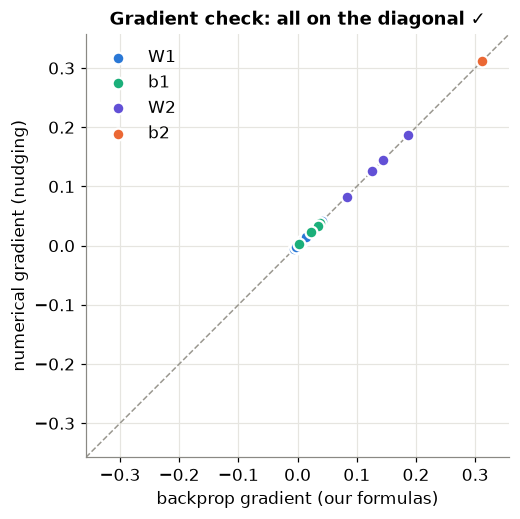

In [17]:
net = ShallowNet(2, 4, seed=1)
net.forward(X); analytic = net.backward(Y)

eps, numeric, exact, labels = 1e-5, [], [], []
for name, P in net.params().items():
    for idx in np.ndindex(P.shape):
        old = P[idx]
        P[idx] = old + eps; net.forward(X); L_plus  = net.loss(Y)
        P[idx] = old - eps; net.forward(X); L_minus = net.loss(Y)
        P[idx] = old
        numeric.append((L_plus - L_minus) / (2 * eps)); exact.append(analytic[name][idx]); labels.append(name)

numeric, exact = np.array(numeric), np.array(exact)
print(f"checked {len(exact)} parameters, largest difference: {np.abs(numeric - exact).max():.2e}")

fig, ax = plt.subplots(figsize=(5.2, 5))
lim = np.abs(exact).max() * 1.15
ax.plot([-lim, lim], [-lim, lim], color=GRAY, lw=1, ls="--")
for name, col in zip(["W1", "b1", "W2", "b2"], [BLUE, AQUA, VIOLET, ORANGE]):
    m = np.array(labels) == name
    ax.scatter(exact[m], numeric[m], s=60, color=col, edgecolor="white", lw=1.5, label=name, zorder=3)
ax.set(xlabel="backprop gradient (our formulas)", ylabel="numerical gradient (nudging)", title="Gradient check: all on the diagonal ✓",
       xlim=(-lim, lim), ylim=(-lim, lim)); ax.set_aspect("equal"); ax.legend(loc="upper left")
plt.show()

In [18]:
def train(net, X, Y, epochs=300, lr=0.5, batch_size=64, seed=0, snapshot_every=None):
    # Mini-batch SGD, as in the SGD chapter. Returns loss history (+ optional snapshots of predictions).
    rng = np.random.default_rng(seed)
    history, snaps = [], []
    for epoch in range(epochs):
        order = rng.permutation(len(X))
        for start in range(0, len(X), batch_size):
            idx = order[start:start + batch_size]
            net.forward(X[idx])
            net.step(net.backward(Y[idx]), lr)
        net.forward(X); history.append(net.loss(Y))
        if snapshot_every and (epoch % snapshot_every == 0 or epoch == epochs - 1):
            snaps.append((epoch, net.predict(GRID).copy()))
    return (history, snaps) if snapshot_every else history

Now we can go back to the **wage profile** from Section 4 and let the network find the kinks on its own, with 1, 2, 5 and 20 hidden units. The bottom row shows **each hidden unit's contribution** (a bent line, zero where the unit is off); the orange line on top is their sum.

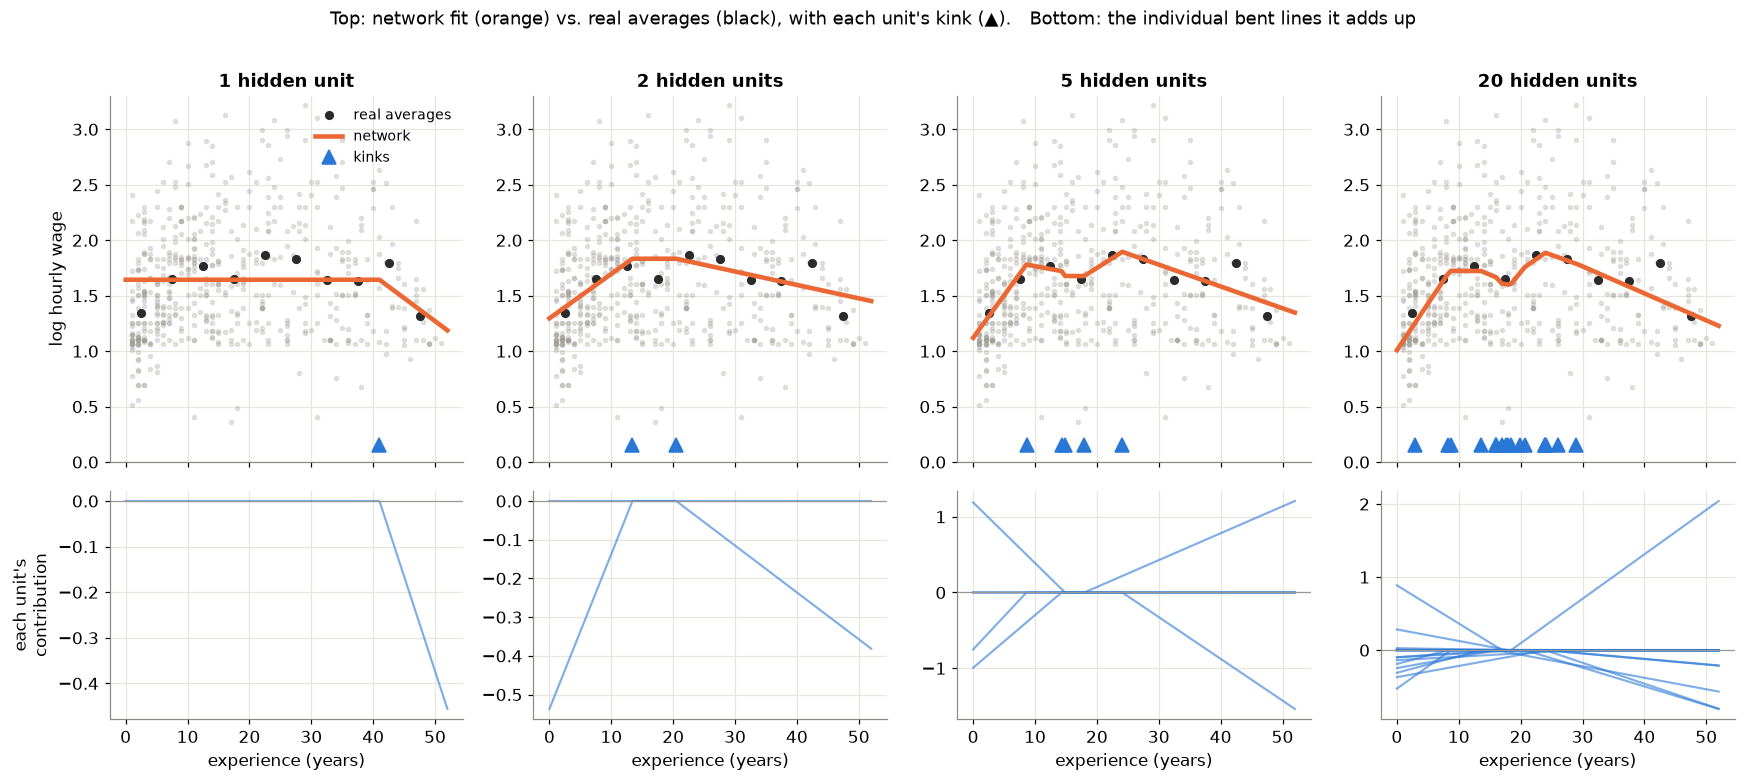

In [19]:
ex_std = (exper - exper.mean()) / exper.std()
logw_c = logw - logw.mean()
Xw, Yw = ex_std[:, None], logw_c[:, None]
ex_grid = np.linspace(0, 52, 400); ex_grid_std = ((ex_grid - exper.mean()) / exper.std())[:, None]

fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharex=True, gridspec_kw={"height_ratios": [1.6, 1]})
for j, H in enumerate([1, 2, 5, 20]):
    wnet = ShallowNet(1, H, output="linear", seed=3)
    train(wnet, Xw, Yw, epochs=600, lr=0.05, batch_size=64)
    wnet.forward(ex_grid_std)
    contributions = wnet.A1 * wnet.W2[:, 0]          # each hidden unit's piece of the output (0 where 'off')
    kinks = -wnet.b1 / wnet.W1[0] * exper.std() + exper.mean()   # where each unit switches on, in years
    top, bot = axes[0, j], axes[1, j]
    top.scatter(exper, logw, s=7, color=GRAY, alpha=.25)
    top.plot(mid, bin_mean, "o", color=INK, ms=5, label="real averages")
    top.plot(ex_grid, wnet.out[:, 0] + logw.mean(), color=ORANGE, lw=3, label="network")
    k_in = kinks[(kinks > 0) & (kinks < 52)]
    top.plot(k_in, np.full_like(k_in, 0.15), "^", color=BLUE, ms=9, label="kinks")
    top.set(title=f"{H} hidden unit{'s' if H > 1 else ''}", ylim=(0, 3.3))
    for k in range(H):
        bot.plot(ex_grid, contributions[:, k], color=BLUE, alpha=.6, lw=1.4)
    bot.axhline(0, color=GRAY, lw=.8)
    bot.set(xlabel="experience (years)")
axes[0, 0].set_ylabel("log hourly wage"); axes[1, 0].set_ylabel("each unit's\ncontribution")
axes[0, 0].legend(loc="upper right", fontsize=9)
fig.suptitle("Top: network fit (orange) vs. real averages (black), with each unit's kink (▲).   Bottom: the individual bent lines it adds up",
             y=1.01, fontsize=12)
plt.tight_layout(); plt.show()

- **1 unit:** one bend, so it can only rise and then go flat.
- **2 units:** rise, then decline.
- **5 units:** the concave profile, *discovered from the data* without specifying any $\text{exper}^2$ term. The kinks (▲) cluster where the curve actually bends.
- **20 units:** it starts chasing noise, such as the small dip around 17 years. That's a first glimpse of **overfitting**: more units means more freedom, including the freedom to fit noise.

This is the intuition behind the **Universal Approximation Theorem**: with enough hidden units, a single hidden layer can approximate any reasonable function.

## 6. Training on the coffee shops, and looking inside

Back to 2D. We train a network with **4 hidden ReLU units** and take snapshots of its decision boundary as it learns.

final accuracy: 97.0%   (single neuron: 75.8%)


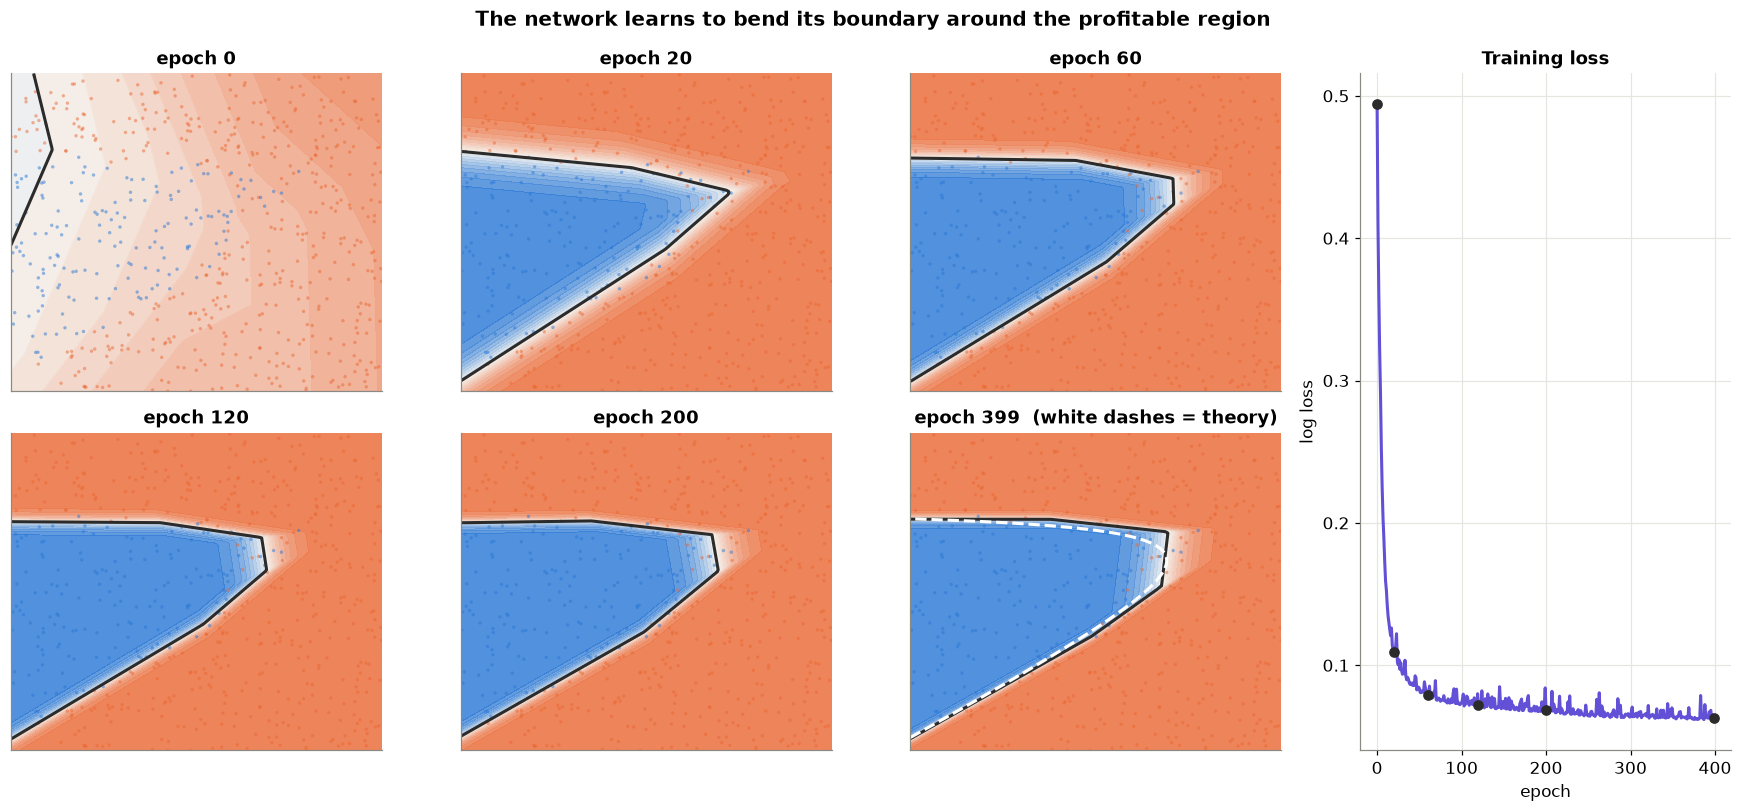

In [20]:
net = ShallowNet(2, 4, seed=1)
history, snaps = train(net, X, Y, epochs=400, lr=0.5, snapshot_every=20)
acc = ((net.predict(X) > .5) == y).mean()
print(f"final accuracy: {acc:.1%}   (single neuron: {acc_single:.1%})")

show = [0, 1, 3, 6, 10, len(snaps) - 1]
fig = plt.figure(figsize=(16, 7.5))
for k, s in enumerate(show):
    ax = fig.add_subplot(2, 4, [1, 2, 3, 5, 6, 7][k])
    epoch, prob = snaps[s]
    ax.contourf(GRID_C, GRID_P, prob.reshape(GRID_C.shape), levels=np.linspace(0, 1, 21), cmap=PROB_CMAP, alpha=.85)
    ax.contour(GRID_C, GRID_P, prob.reshape(GRID_C.shape), levels=[.5], colors=INK, linewidths=2)
    ax.scatter(cost, price, c=np.where(y == 1, BLUE, ORANGE), s=5, alpha=.5, edgecolors="none")
    ax.set_title(f"epoch {epoch}"); ax.grid(False); ax.set_xticks([]); ax.set_yticks([])
    if k == len(show) - 1:
        ax.contour(GRID_C, GRID_P, (GRID_P - GRID_C) * np.maximum(10 - GRID_P, 0) - 5, levels=[0], colors="white", linewidths=2, linestyles="--")
        ax.set_title(f"epoch {epoch}  (white dashes = theory)")
axL = fig.add_subplot(1, 4, 4)
axL.plot(history, color=VIOLET)
for s in show:
    axL.plot(snaps[s][0], history[snaps[s][0]], "o", color=INK, ms=6)
axL.set(title="Training loss", xlabel="epoch", ylabel="log loss")
fig.suptitle("The network learns to bend its boundary around the profitable region", fontsize=13, weight="bold")
plt.tight_layout(); plt.show()

### Optional: an animation of the same training run
Saves `training.gif` next to the notebook and shows it below (takes ~20 seconds).

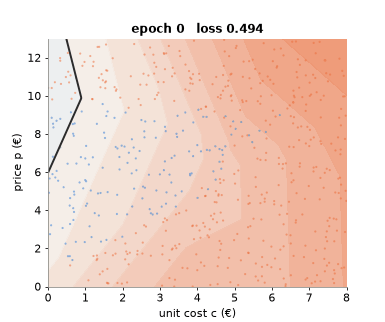

In [21]:
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image

fig, ax = plt.subplots(figsize=(5.5, 4.6))
def frame(i):
    ax.clear(); epoch, prob = snaps[i]
    ax.contourf(GRID_C, GRID_P, prob.reshape(GRID_C.shape), levels=np.linspace(0, 1, 21), cmap=PROB_CMAP, alpha=.85)
    ax.contour(GRID_C, GRID_P, prob.reshape(GRID_C.shape), levels=[.5], colors=INK, linewidths=2)
    ax.scatter(cost, price, c=np.where(y == 1, BLUE, ORANGE), s=5, alpha=.5, edgecolors="none")
    ax.set(title=f"epoch {epoch}   loss {history[epoch]:.3f}", xlabel="unit cost c (€)", ylabel="price p (€)"); ax.grid(False)
FuncAnimation(fig, frame, frames=len(snaps)).save("training.gif", writer=PillowWriter(fps=4), dpi=70)
plt.close(fig)
Image("training.gif")

### Looking inside: what did each hidden unit learn?

Each hidden unit is a **ReLU of a straight line** in the (cost, price) plane. It is 0 on one side of its line and grows on the other. The output neuron adds them up (with positive or negative weights) and squashes the result with the sigmoid.

Below: the activation of each hidden unit (dark = strongly active), its weight $W_2$ into the output, and the final combination.

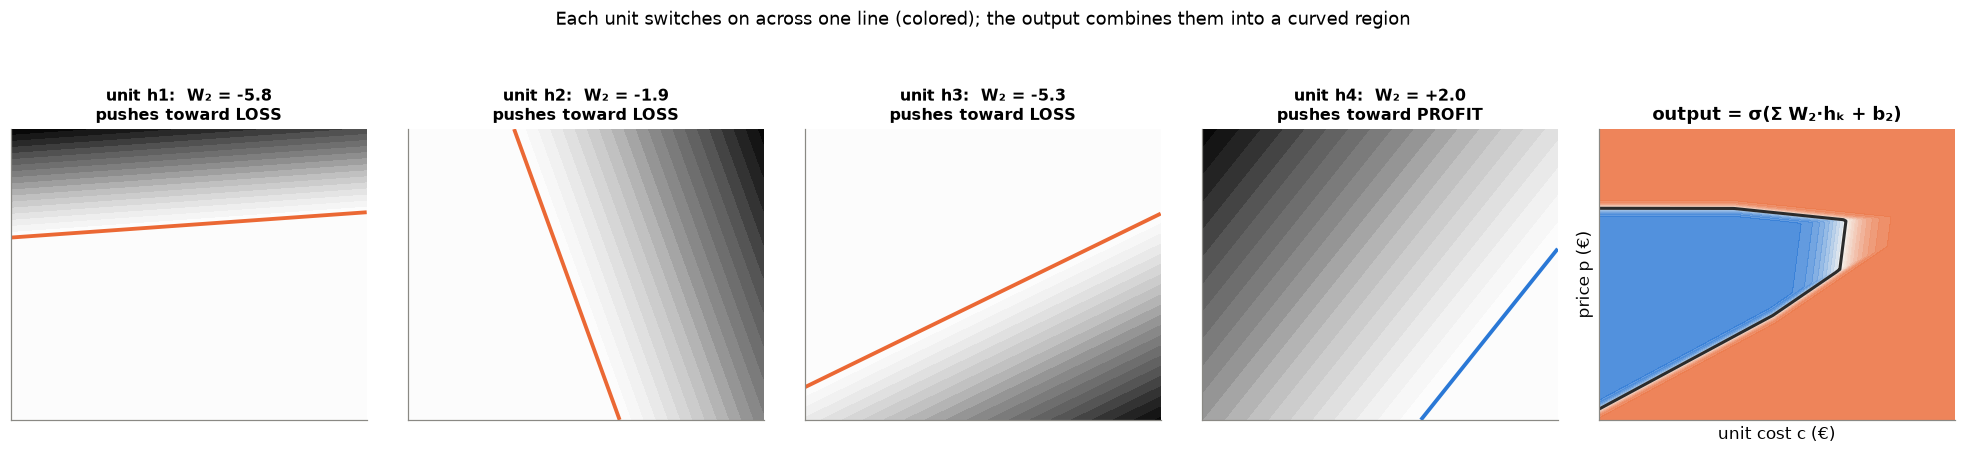

In [22]:
net.forward(GRID)
fig, axes = plt.subplots(1, 5, figsize=(18, 3.9))
for k in range(4):
    ax = axes[k]
    act = net.A1[:, k].reshape(GRID_C.shape)
    ax.contourf(GRID_C, GRID_P, act, levels=20, cmap="Greys")
    ax.contour(GRID_C, GRID_P, net.Z1[:, k].reshape(GRID_C.shape), levels=[0], colors=BLUE if net.W2[k, 0] > 0 else ORANGE, linewidths=2.5)
    sign = "pushes toward PROFIT" if net.W2[k, 0] > 0 else "pushes toward LOSS"
    ax.set_title(f"unit h{k+1}:  W₂ = {net.W2[k, 0]:+.1f}\n{sign}", fontsize=10.5); ax.grid(False)
    ax.set_xticks([]); ax.set_yticks([])
plot_boundary(axes[4], net.predict, "output = σ(Σ W₂·hₖ + b₂)", points=False)
axes[4].set_xticks([]); axes[4].set_yticks([])
fig.suptitle("Each unit switches on across one line (colored); the output combines them into a curved region", y=1.05, fontsize=12)
plt.tight_layout(); plt.show()

Read this like an economist would. Typically you'll find units that say something like:
- *"price is high relative to cost"* → pushes toward **profit** (margin is positive)
- *"price is very high"* → pushes toward **loss** (demand collapses)
- *"cost is high"* → pushes toward **loss**

Put together, they carve out the tongue-shaped region. The network has rediscovered the economics of the profit band, without ever seeing the demand curve. (The exact units vary with the random seed; try changing it.)

## 7. Three practical issues

### 7a. How many hidden units?

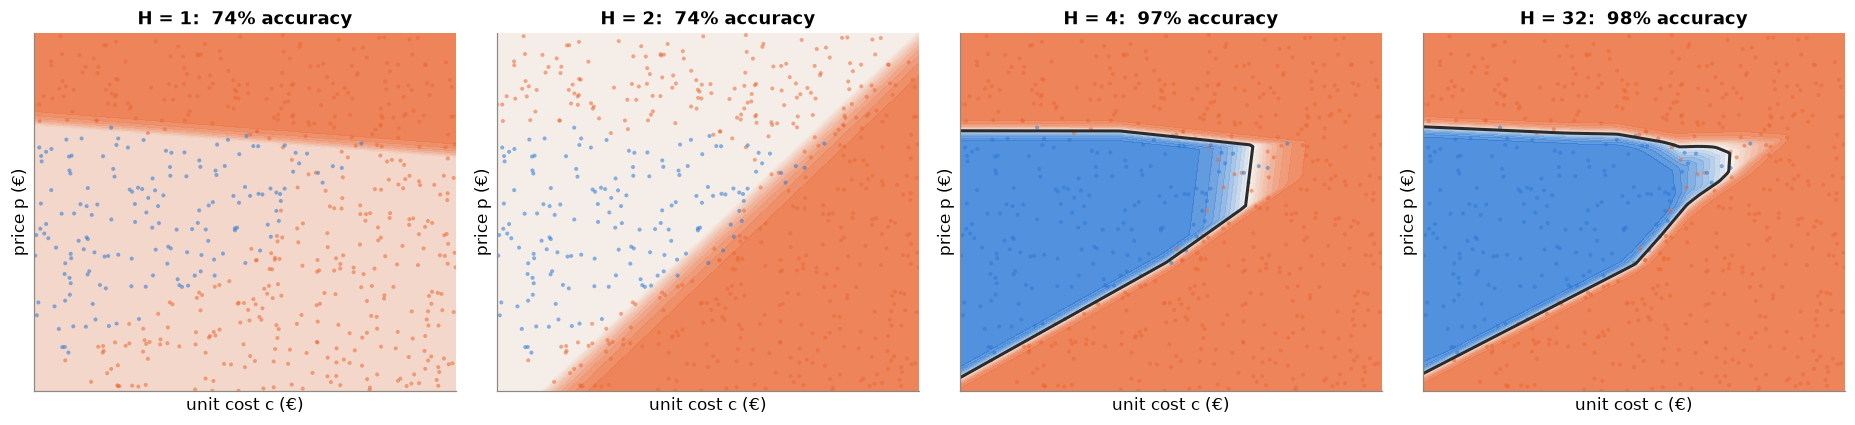

In [23]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, H in zip(axes, [1, 2, 4, 32]):
    m = ShallowNet(2, H, seed=1); train(m, X, Y, epochs=400, lr=0.5)
    acc_H = ((m.predict(X) > .5) == y).mean()
    plot_boundary(ax, m.predict, f"H = {H}:  {acc_H:.0%} accuracy")
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

- **H = 1 or 2:** too few lines to fence in the region (*underfitting*).
- **H = 4:** enough, because the region has roughly 3–4 "sides".
- **H = 32:** about the same here. More units mean more capacity, and with little data that can turn into **overfitting** (memorizing noise). This is a topic we will cover in regularization later.

### 7b. Why not start all weights at zero (or at any common value)?

Tempting, since it seems "neutral". But if every hidden unit starts identical, every unit receives **identical gradients**, so they stay identical forever. The network has 4 units in name but behaves like **one**. This is called the *symmetry problem*. (With ReLU and exactly zero weights it's even worse: every gradient is zero and nothing moves at all.) Random initialization breaks the symmetry.

Below, we start all units with the same weights and track the weight from *price* into each unit.

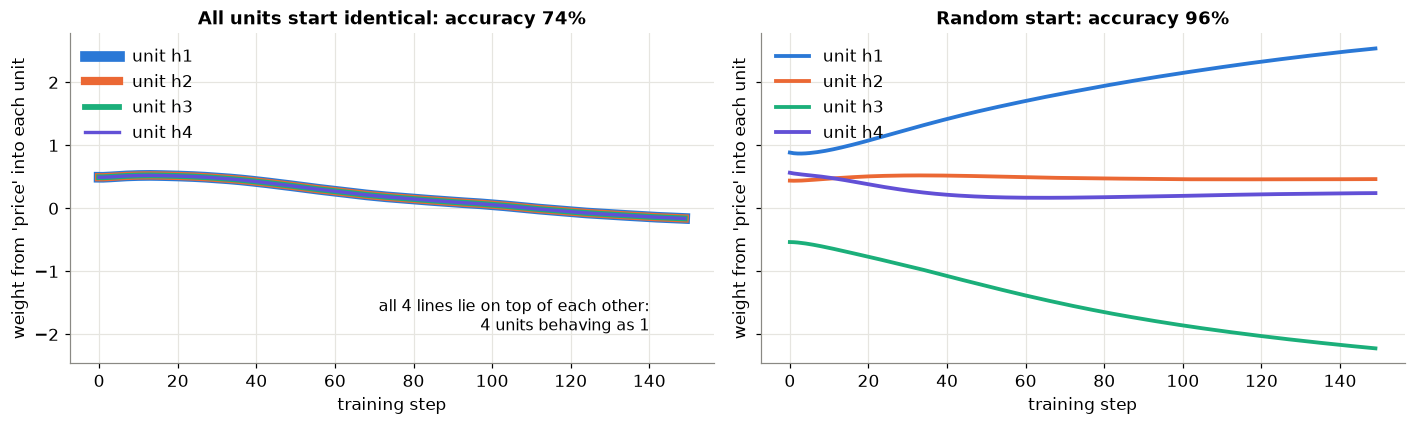

In [24]:
def weight_paths(init, epochs=150):
    m = ShallowNet(2, 4, init=init, seed=1)
    paths = []
    for e in range(epochs):
        # weight from 'price' to each unit
        m.forward(X); m.step(m.backward(Y), 0.5); paths.append(m.W1[1].copy())
    m.forward(X)
    return np.array(paths), ((m.predict(X) > .5) == y).mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, init, title in zip(axes, ["same", "random"], ["All units start identical", "Random start"]):
    paths, acc_i = weight_paths(init)
    for k, col in enumerate([BLUE, ORANGE, AQUA, VIOLET]):
        ax.plot(paths[:, k], color=col, lw=2.5 if init == "random" else 7 - k * 1.6, label=f"unit h{k+1}")
    ax.set(title=f"{title}: accuracy {acc_i:.0%}", xlabel="training step", ylabel="weight from 'price' into each unit")
    ax.legend(loc="upper left")
axes[0].text(140, axes[0].get_ylim()[0] + .1 * np.ptp(axes[0].get_ylim()), "all 4 lines lie on top of each other:\n4 units behaving as 1", fontsize=10.5, ha="right")
plt.tight_layout(); plt.show()

### 7c. Which hidden activation?

All three activations from the previous chapter work in principle. In practice they train at very different speeds, because of their **derivatives**: sigmoid's slope is at most 0.25 and almost 0 at the extremes, so the blame shrinks every time it passes back through a sigmoid. ReLU passes blame through with slope exactly 1 wherever it is active.

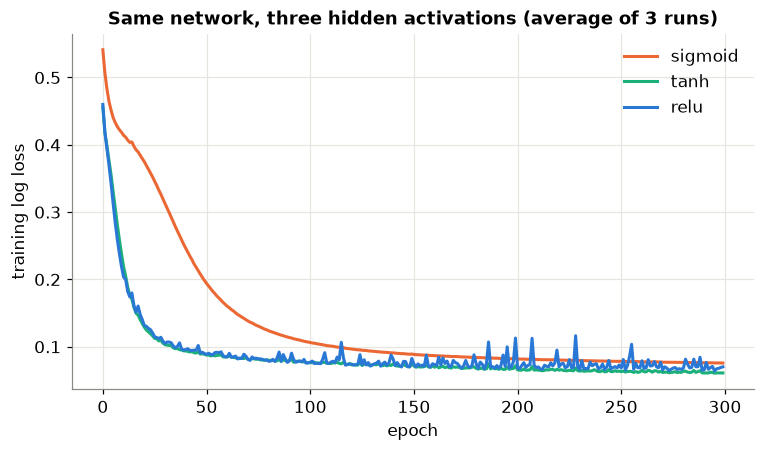

In [25]:
fig, ax = plt.subplots(figsize=(8, 4.2))
for act, col in zip(["sigmoid", "tanh", "relu"], [ORANGE, AQUA, BLUE]):
    curves = [train(ShallowNet(2, 8, activation=act, seed=s), X, Y, epochs=300, lr=0.5, seed=s) for s in range(3)]
    ax.plot(np.mean(curves, 0), color=col, label=act)
ax.set(title="Same network, three hidden activations (average of 3 runs)", xlabel="epoch", ylabel="training log loss")
ax.legend(); plt.show()

Sigmoid hidden units learn much more slowly. With only one hidden layer, tanh and ReLU are about equally fast. ReLU's advantage grows with **depth**: in a deep network the blame passes back through many activations, and sigmoid's ≤ 0.25 slopes multiply into almost nothing (the *vanishing gradient*). ReLU is also cheaper to compute, which is why it is the default hidden activation.

## 8. Bridge to PyTorch: `loss.backward()` Coming Next Week

From the next chapter on we'll use PyTorch. Before trusting it, let's check that it computes *exactly* what we derived. We build the same network, copy in the same starting weights, and compare.

One detail: PyTorch's `nn.Linear` stores weights as `(out, in)`, the transpose of our `(in, out)` convention. You should read more about Pytorch Docummentation or in my opinion the best book out there: *Deep Learning with PyTorch by Eli Stevens, Luca Antiga, and Thomas Viehmann*: https://www.oreilly.com/library/view/deep-learning-with/9781617295263/

In [26]:
import torch
import torch.nn as nn
# match NumPy's precision so we can compare exactly
torch.set_default_dtype(torch.float64)

class TorchShallowNet(nn.Module):
    def __init__(self, n_in, n_hidden):
        super().__init__()
        self.hidden = nn.Linear(n_in, n_hidden)  # this is W1, b1
        self.output = nn.Linear(n_hidden, 1)     # this is W2, b2
    def forward(self, x):
        return torch.sigmoid(self.output(torch.relu(self.hidden(x))))

np_net = ShallowNet(2, 4, seed=1)
t_net = TorchShallowNet(2, 4)
with torch.no_grad():
    # copy our NumPy weights into PyTorch
    t_net.hidden.weight.copy_(torch.tensor(np_net.W1.T)); t_net.hidden.bias.copy_(torch.tensor(np_net.b1))
    t_net.output.weight.copy_(torch.tensor(np_net.W2.T)); t_net.output.bias.copy_(torch.tensor(np_net.b2))

Xt, Yt = torch.tensor(X), torch.tensor(Y)

# NumPy: our hand-written backprop
np_net.forward(X); g_np = np_net.backward(Y)
# PyTorch: automatic differentiation
loss_t = nn.functional.binary_cross_entropy(t_net(Xt), Yt)
loss_t.backward()
g_t = {"W1": t_net.hidden.weight.grad.T.numpy(), "b1": t_net.hidden.bias.grad.numpy(),
       "W2": t_net.output.weight.grad.T.numpy(), "b2": t_net.output.bias.grad.numpy()}

print(f"loss  NumPy: {np_net.loss(Y):.10f}   PyTorch: {loss_t.item():.10f}\n")
print("dW1 (ours):\n", g_np["W1"], "\n\ndW1 (PyTorch):\n", g_t["W1"])
print("\nlargest difference over all parameters:",
      max(np.abs(g_np[k] - g_t[k]).max() for k in g_np))

loss  NumPy: 0.7640106923   PyTorch: 0.7640106923

dW1 (ours):
 [[ 0.007  0.029  0.001 -0.006]
 [ 0.042  0.014 -0.003  0.034]] 

dW1 (PyTorch):
 [[ 0.007  0.029  0.001 -0.006]
 [ 0.042  0.014 -0.003  0.034]]

largest difference over all parameters: 1.3877787807814457e-16


Identical, to about 16 decimal places. Now let's train both side by side, with the same mini-batches and the same learning rate, and overlay the loss curves.

Note how much shorter the PyTorch training loop is: `zero_grad → forward → loss → backward → step`. That five-line pattern will be in every notebook from now on. You should know this better than your Birthdays

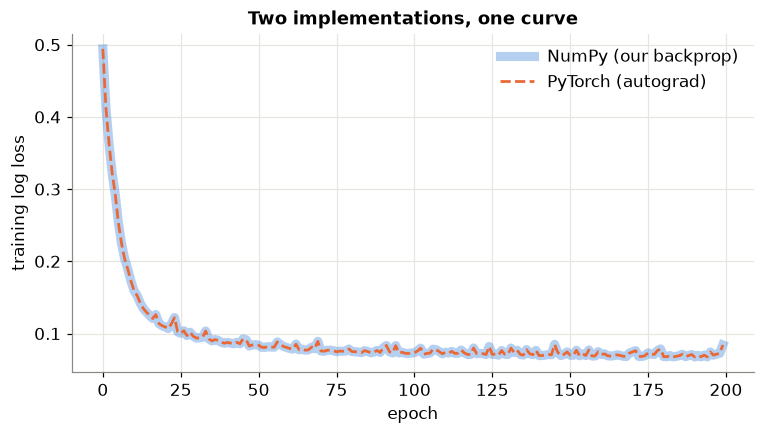

max difference between the two loss curves: 1.899858048659553e-10


In [27]:
np_net = ShallowNet(2, 4, seed=1)
t_net = TorchShallowNet(2, 4)
with torch.no_grad():
    t_net.hidden.weight.copy_(torch.tensor(np_net.W1.T)); t_net.hidden.bias.copy_(torch.tensor(np_net.b1))
    t_net.output.weight.copy_(torch.tensor(np_net.W2.T)); t_net.output.bias.copy_(torch.tensor(np_net.b2))

hist_np = train(np_net, X, Y, epochs=200, lr=0.5, batch_size=64, seed=0)

opt = torch.optim.SGD(t_net.parameters(), lr=0.5)
# same shuffling as our train() function
rng = np.random.default_rng(0)
hist_t = []
for epoch in range(200):
    order = rng.permutation(len(X))
    for start in range(0, len(X), 64):
        idx = torch.tensor(order[start:start + 64])
        # 1. reset gradients
        opt.zero_grad()
        # 2-3. forward + loss
        loss = nn.functional.binary_cross_entropy(t_net(Xt[idx]), Yt[idx])
        # 4. backprop (automatic!)
        loss.backward()
        # 5. SGD update
        opt.step()
    with torch.no_grad():
        hist_t.append(nn.functional.binary_cross_entropy(t_net(Xt), Yt).item())

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(hist_np, color=BLUE, lw=6, alpha=.35, label="NumPy (our backprop)")
ax.plot(hist_t, color=ORANGE, lw=1.8, ls="--", label="PyTorch (autograd)")
ax.set(title="Two implementations, one curve", xlabel="epoch", ylabel="training log loss"); ax.legend()
plt.show()
print("max difference between the two loss curves:", np.abs(np.array(hist_np) - np.array(hist_t)).max())

## 9. Reality check: a neural network is not magic

The coffee-shop data was **simulated** from an economic model with a strongly curved boundary. Real data is often much closer to linear. Here is the classic **Mroz (1987)** dataset: 753 married women in the US, and whether they participated in the labour force (`inlf`), predicted from years of **experience** and **number of young children**.

We hold out 30% of the data as a test set and compare the single neuron (logistic regression) with our shallow network.

In [28]:
mroz = wooldridge.data("mroz")
mroz.head()

,inlf,hours,kidslt6,kidsge6,age,educ,wage,repwage,hushrs,husage,...,faminc,mtr,motheduc,fatheduc,unem,city,exper,nwifeinc,lwage,expersq
0,1,1610,1,0,32,12,3.3540,2.65,2708,34,...,16310.0,0.7215,12,7,5.0,0,14,10.910060,1.210154,196
1,1,1656,0,2,30,12,1.3889,2.65,2310,30,...,21800.0,0.6615,7,7,11.0,1,5,19.499981,0.328512,25
2,1,1980,1,3,35,12,4.5455,4.04,3072,40,...,21040.0,0.6915,12,7,5.0,0,15,12.039910,1.514138,225
3,1,456,0,3,34,12,1.0965,3.25,1920,53,...,7300.0,0.7815,7,7,5.0,0,6,6.799996,0.092123,36
4,1,1568,1,2,31,14,4.5918,3.60,2000,32,...,27300.0,0.6215,12,14,9.5,1,7,20.100058,1.524272,49


In [29]:
feats = ["exper", "kidslt6"]
Xm_raw = mroz[feats].values.astype(float); ym = mroz["inlf"].values.astype(float)
Xm = (Xm_raw - Xm_raw.mean(0)) / Xm_raw.std(0)

rng = np.random.default_rng(0); perm = rng.permutation(len(ym)); cut = int(.7 * len(ym))
tr, te = perm[:cut], perm[cut:]

results = {}
for name, H in [("1 neuron\n(logistic)", None), ("shallow net\nH = 8", 8), ("shallow net\nH = 32", 32)]:
    if H is None:
        wm, bm = np.zeros((2, 1)), 0.0
        for _ in range(3000):
            pm = sigmoid(Xm[tr] @ wm + bm); g = (pm - ym[tr, None]) / len(tr)
            wm -= 0.5 * Xm[tr].T @ g; bm -= 0.5 * g.sum()
        p_te = sigmoid(Xm[te] @ wm + bm)[:, 0]
    else:
        m = ShallowNet(2, H, seed=0); train(m, Xm[tr], ym[tr, None], epochs=300, lr=0.2)
        p_te = m.predict(Xm[te])
    results[name] = ((p_te > .5) == ym[te]).mean()

results

{'1 neuron\n(logistic)': np.float64(0.672566371681416),
 'shallow net\nH = 8': np.float64(0.6637168141592921),
 'shallow net\nH = 32': np.float64(0.6769911504424779)}

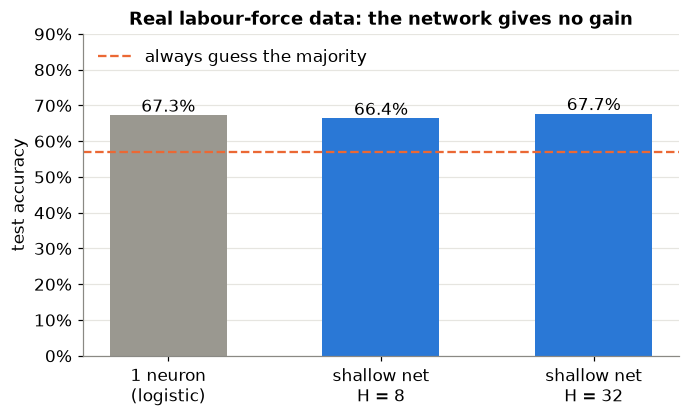

In [30]:
fig, ax = plt.subplots(figsize=(7, 3.8))
bars = ax.bar(list(results), list(results.values()), color=[GRAY, BLUE, BLUE], width=.55)
for bar, v in zip(bars, results.values()):
    ax.text(bar.get_x() + bar.get_width() / 2, v + .01, f"{v:.1%}", ha="center", fontsize=11)
ax.axhline(max(ym[te].mean(), 1 - ym[te].mean()), color=ORANGE, ls="--", lw=1.5, label="always guess the majority")
ax.set(ylim=(0, .9), ylabel="test accuracy", title="Real labour-force data: the network gives no gain")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0)); ax.legend(loc="upper left")
ax.grid(axis="x"); plt.show()

**No real gain.** The relationship in this data is close to linear in the features, so the extra flexibility has nothing to find, and the network just adds parameters to tune and a model that is harder to interpret.

**Things to keep in mind:**
1. Neural nets shine when the relationship is genuinely **non-linear or interactive** and you *don't know its form in advance* (like the profit band, or the wage profile, if we hadn't known to add exper²).
2. When economic theory already tells you the functional form, a simple model is often just as good, and far easier to interpret.
3. Always compare against a simple baseline on **held-out** data.
4. Although NNs are awesome, there are many docummented cases where a simple logistic regression or linear regression beats them, so always start simple!

---
## Summary

| Concept | One-liner |
|---|---|
| Hidden layer | Many neurons in parallel, then one neuron combining them |
| Forward pass | $X \to XW_1+b_1 \to \text{ReLU} \to A_1W_2+b_2 \to \sigma$ |
| Hidden units | Each one is a bent line (1D) or bent plane (2D). Sums of them can build any shape |
| Backprop | Blame flows backwards. Per layer: weight grad = inputᵀ × blame; pass blame back through weights and activation |
| Gradient check | Nudge each weight and compare. Always do this once when you write backprop by hand |
| Initialization | Random, never all-zero (symmetry) |
| Activation | ReLU trains fastest; sigmoid's small slopes slow learning |
| PyTorch | `loss.backward()` = our `backward()`, verified to 16 decimals |

**Next chapter:** deep networks. What changes when we stack many hidden layers, and why training gets harder (vanishing gradients, which you already got a taste of in 7c).

---
## Exercises

**Disclaimer**: These exercises I have collected from code and exercises of online courses I used to take in the past. If you want to learn, you have to break things and figure out how it happened.

1. **Change the economics.** Make demand steeper, e.g. $Q = 10 - 2p$ (so the choke price is €5). How does the profitable region change? How many hidden units do you now need?
2. **Break the gradient check.** Introduce a bug in `backward()` (e.g. forget the `/ n`, or use `self.Z1 > 0` with `sigmoid`). What does the gradient-check plot look like?
3. **Learning rate.** Retrain the coffee-shop network with `lr = 0.01`, `0.5` and `5`. Plot the three loss curves on one chart. Connect what you see to the SGD chapter.
4. **Wage profile with education.** Use both `exper` and `educ` from `wage1` as inputs (so `ShallowNet(2, H, output="linear")`). Plot predicted log wage against experience for workers with 12 vs 16 years of education. Do the profiles have the same shape?
5. **Mroz with more features.** Add `age`, `educ` and `nwifeinc`. Does the network beat logistic regression now?